# New Dataset – Step 3: Which Model is Best?

Same analysis as `3_LLM_Comparision_...ipynb` (paper, Section 4.2), now with **4 models** and **3 approaches**.

For every approach and metric:
* **Friedman test** over the 4 related model outputs (same input texts)
* **Kendall's W** as effect size
* If Friedman p < 0.05: pairwise **Wilcoxon signed-rank tests** with **Bonferroni** correction (6 pairs)
* **Winner** = best mean (lower = better, except FRE = higher is better)
* A win is **significant** when the winner is significantly better than at least one other model.

**Changes compared to the old notebook**
* Kendall's W is computed as `W = χ²_Friedman / (n · (k − 1))`. The old function ranked the texts inside each model
  instead of the models inside each text.
* WSF is treated as **lower = better** (in the old code it was "higher = better", which contradicts the paper text).

The main comparison uses **all 10 texts** (n = 10). Legal and medical (n = 5 each) are also shown, but with n = 5
the Wilcoxon test can never reach p < 0.05 (smallest possible p = 0.0625), so only the Friedman test is informative there.

| Name | Pipeline |
|---|---|
| **Original** | official German source text (`Source_Texts_German`, human, same for all models) |
| **Approach_1** | English → English Easy → German Easy |
| **Approach_2** | English → standard German → German Easy |
| **Approach_3** | English → German Easy (direct) |

Scores come from `New_dataset_1_Metric_Scores.ipynb` (`New dataset/<model>/Matrix_Scores_<model>.csv`).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations
from statsmodels.stats.multitest import multipletests

DATA_DIR = "New dataset"
RESULTS_DIR = os.path.join(DATA_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Short name -> folder name
MODELS = {
    "DeepSeek-V4-Flash": "deepseek-v4-flash-0731",
    "Gemma-4-31B":       "gemma-4-31b-it",
    "Llama-3.1-8B":      "meta-llama-3.1-8b-instruct",
    "Qwen3.5-397B":      "qwen3.5-397b-a17b",
}
APPROACHES = ["Approach_1", "Approach_2", "Approach_3"]

METRICS = ["TTR", "LD", "WR", "MDD", "SI", "Cross", "WSF", "LIX", "FRE", "Fog"]
LEXICAL_METRICS = ["TTR", "LD", "WR"]
SYNTACTIC_METRICS = ["MDD", "SI", "Cross"]
READABILITY_METRICS = ["WSF", "LIX", "FRE", "Fog"]

# Direction (as defined in the paper): lower = better for all metrics except FRE
HIGHER_BETTER = ["FRE"]

MODEL_COLORS = {
    "Original":          "#7f7f7f",
    "DeepSeek-V4-Flash": "#1f77b4",
    "Gemma-4-31B":       "#ff7f0e",
    "Llama-3.1-8B":      "#2ca02c",
    "Qwen3.5-397B":      "#d62728",
}
APPROACH_COLORS = {"Original": "#7f7f7f", "Approach_1": "#8dd3c7", "Approach_2": "#fdb462", "Approach_3": "#bebada"}

scores = {
    name: pd.read_csv(os.path.join(DATA_DIR, folder, f"Matrix_Scores_{folder}.csv")).sort_values("ID").reset_index(drop=True)
    for name, folder in MODELS.items()
}

# All models must contain the same texts in the same order (paired tests)
for df in scores.values():
    assert list(df["ID"]) == list(scores["Qwen3.5-397B"]["ID"])

In [2]:
def kendalls_w(friedman_stat, n, k):
    return friedman_stat / (n * (k - 1))


def safe_wilcoxon(a, b):
    if np.allclose(a, b):
        return 1.0
    return wilcoxon(a, b).pvalue


def is_better(metric, a, b):
    return a > b if metric in HIGHER_BETTER else a < b


def compare_models(scores, version, domain="All"):
    data = {}
    for model, df in scores.items():
        if domain != "All":
            df = df[df["Domain"] == domain]
        data[model] = df.reset_index(drop=True)

    wins_all = {model: 0 for model in data}
    wins_significant = {model: 0 for model in data}
    rows = []

    for metric in METRICS:
        tmp = pd.DataFrame({model: df[f"{metric}_{version}"].astype(float) for model, df in data.items()})
        n, k = tmp.shape

        # ---------- Friedman Test + Kendall's W ----------
        stat, p_value = friedmanchisquare(*[tmp[c] for c in tmp.columns])
        W = kendalls_w(stat, n, k)

        # ---------- Descriptive winner ----------
        means = tmp.mean()
        best_model = means.idxmax() if metric in HIGHER_BETTER else means.idxmin()
        wins_all[best_model] += 1

        # ---------- Post-hoc: Wilcoxon + Bonferroni ----------
        significant_pairs = []
        if p_value < 0.05:
            pairs = list(combinations(tmp.columns, 2))
            raw_p = [safe_wilcoxon(tmp[a], tmp[b]) for a, b in pairs]
            adj_p = multipletests(raw_p, method="bonferroni")[1]
            for (a, b), p in zip(pairs, adj_p):
                if p < 0.05:
                    better = a if is_better(metric, means[a], means[b]) else b
                    worse = b if better == a else a
                    significant_pairs.append((better, worse, p))

        posthoc_significant = len(significant_pairs) > 0
        winner_beats = [w for b, w, p in significant_pairs if b == best_model]
        if winner_beats:
            wins_significant[best_model] += 1

        row = {"Metric": metric, "n": n, "Friedman_p": round(p_value, 6), "Kendalls_W": round(W, 4)}
        for model in tmp.columns:
            row[f"{model}_mean"] = round(means[model], 3)
        row["Winner"] = best_model
        row["Posthoc_result"] = "Significant" if posthoc_significant else "Not Significant"
        row["Winner_better_than"] = ", ".join(winner_beats) if winner_beats else "–"
        row["Significant_pairs"] = "; ".join(f"{b} < {w} (p={p:.3f})" if metric not in HIGHER_BETTER
                                             else f"{b} > {w} (p={p:.3f})" for b, w, p in significant_pairs) or "–"
        rows.append(row)

    return pd.DataFrame(rows), wins_all, wins_significant

In [3]:
def plot_model_comparison(result_df, title, file_name):
    fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    axes = axes.flatten()
    models = list(MODELS)

    for ax, (_, row) in zip(axes, result_df.iterrows()):
        values = [row[f"{m}_mean"] for m in models]
        bars = ax.bar(range(len(models)), values, color=[MODEL_COLORS[m] for m in models])
        for bar, v in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
        star = " *" if row["Winner_better_than"] != "–" else ""
        direction = "↑" if row["Metric"] in HIGHER_BETTER else "↓"
        ax.set_title(f"{row['Metric']} ({direction} better){star}")
        ax.set_xticks([])
        ax.set_ylim(0, max(values) * 1.15)
        ax.grid(axis="y", linestyle="--", alpha=0.5)

    handles = [plt.Rectangle((0, 0), 1, 1, color=MODEL_COLORS[m]) for m in models]
    fig.legend(handles, models, loc="lower center", ncol=4, frameon=False)
    fig.suptitle(f"{title}   (* winner significantly better than ≥ 1 model, Bonferroni-corrected)", fontsize=13)
    plt.tight_layout(rect=[0, 0.05, 1, 1])
    plt.savefig(os.path.join(RESULTS_DIR, file_name), dpi=150)
    plt.show()

## All texts (n = 10)

In [4]:
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)

results = {}
wins_all_table = {}
wins_sig_table = {}

for version in APPROACHES:
    print(f"\n======================= {version} | All texts =======================")
    res, wins_all, wins_sig = compare_models(scores, version, "All")
    results[version] = res
    wins_all_table[version] = wins_all
    wins_sig_table[version] = wins_sig
    print(res.drop(columns=["Significant_pairs"]).to_string(index=False))
    print("\nSignificant pairs:")
    for _, r in res.iterrows():
        print(f"  {r['Metric']:6s} {r['Significant_pairs']}")
    print("\nTotal wins (descriptive):", wins_all)
    print("Significant wins:        ", wins_sig)
    res.to_csv(os.path.join(RESULTS_DIR, f"LLM_Comparison_{version}_All.csv"), index=False)


======================= Approach_1 | All texts =======================


Metric  n  Friedman_p  Kendalls_W  DeepSeek-V4-Flash_mean  Gemma-4-31B_mean  Llama-3.1-8B_mean  Qwen3.5-397B_mean            Winner  Posthoc_result                           Winner_better_than
   TTR 10    0.000585      0.5800                   0.448             0.539              0.466              0.422      Qwen3.5-397B     Significant                                  Gemma-4-31B
    LD 10    0.564146      0.0680                   0.481             0.484              0.483              0.493 DeepSeek-V4-Flash Not Significant                                            –
    WR 10    0.034537      0.2879                   0.046             0.029              0.050              0.027      Qwen3.5-397B     Significant                            DeepSeek-V4-Flash
   MDD 10    0.000004      0.9240                   2.425             1.966              2.722              1.638      Qwen3.5-397B     Significant DeepSeek-V4-Flash, Gemma-4-31B, Llama-3.1-8B
    SI 10    0.000007      0.8920  

Metric  n  Friedman_p  Kendalls_W  DeepSeek-V4-Flash_mean  Gemma-4-31B_mean  Llama-3.1-8B_mean  Qwen3.5-397B_mean            Winner  Posthoc_result                           Winner_better_than
   TTR 10    0.000522      0.5880                   0.490             0.557              0.493              0.436      Qwen3.5-397B     Significant                                  Gemma-4-31B
    LD 10    0.591488      0.0636                   0.487             0.487              0.495              0.495 DeepSeek-V4-Flash Not Significant                                            –
    WR 10    0.001713      0.5042                   0.046             0.029              0.087              0.032       Gemma-4-31B     Significant                                 Llama-3.1-8B
   MDD 10    0.000009      0.8680                   1.989             2.023              3.247              1.674      Qwen3.5-397B     Significant DeepSeek-V4-Flash, Gemma-4-31B, Llama-3.1-8B
    SI 10    0.000019      0.8192  

Metric  n  Friedman_p  Kendalls_W  DeepSeek-V4-Flash_mean  Gemma-4-31B_mean  Llama-3.1-8B_mean  Qwen3.5-397B_mean       Winner  Posthoc_result                           Winner_better_than
   TTR 10    0.000585      0.5800                   0.481             0.583              0.474              0.450 Qwen3.5-397B     Significant                                  Gemma-4-31B
    LD 10    0.839878      0.0280                   0.487             0.484              0.486              0.488  Gemma-4-31B Not Significant                                            –
    WR 10    0.000056      0.7444                   0.057             0.032              0.086              0.024 Qwen3.5-397B     Significant              DeepSeek-V4-Flash, Llama-3.1-8B
   MDD 10    0.000003      0.9360                   2.263             2.075              3.342              1.699 Qwen3.5-397B     Significant DeepSeek-V4-Flash, Gemma-4-31B, Llama-3.1-8B
    SI 10    0.000022      0.8080                   0.199   

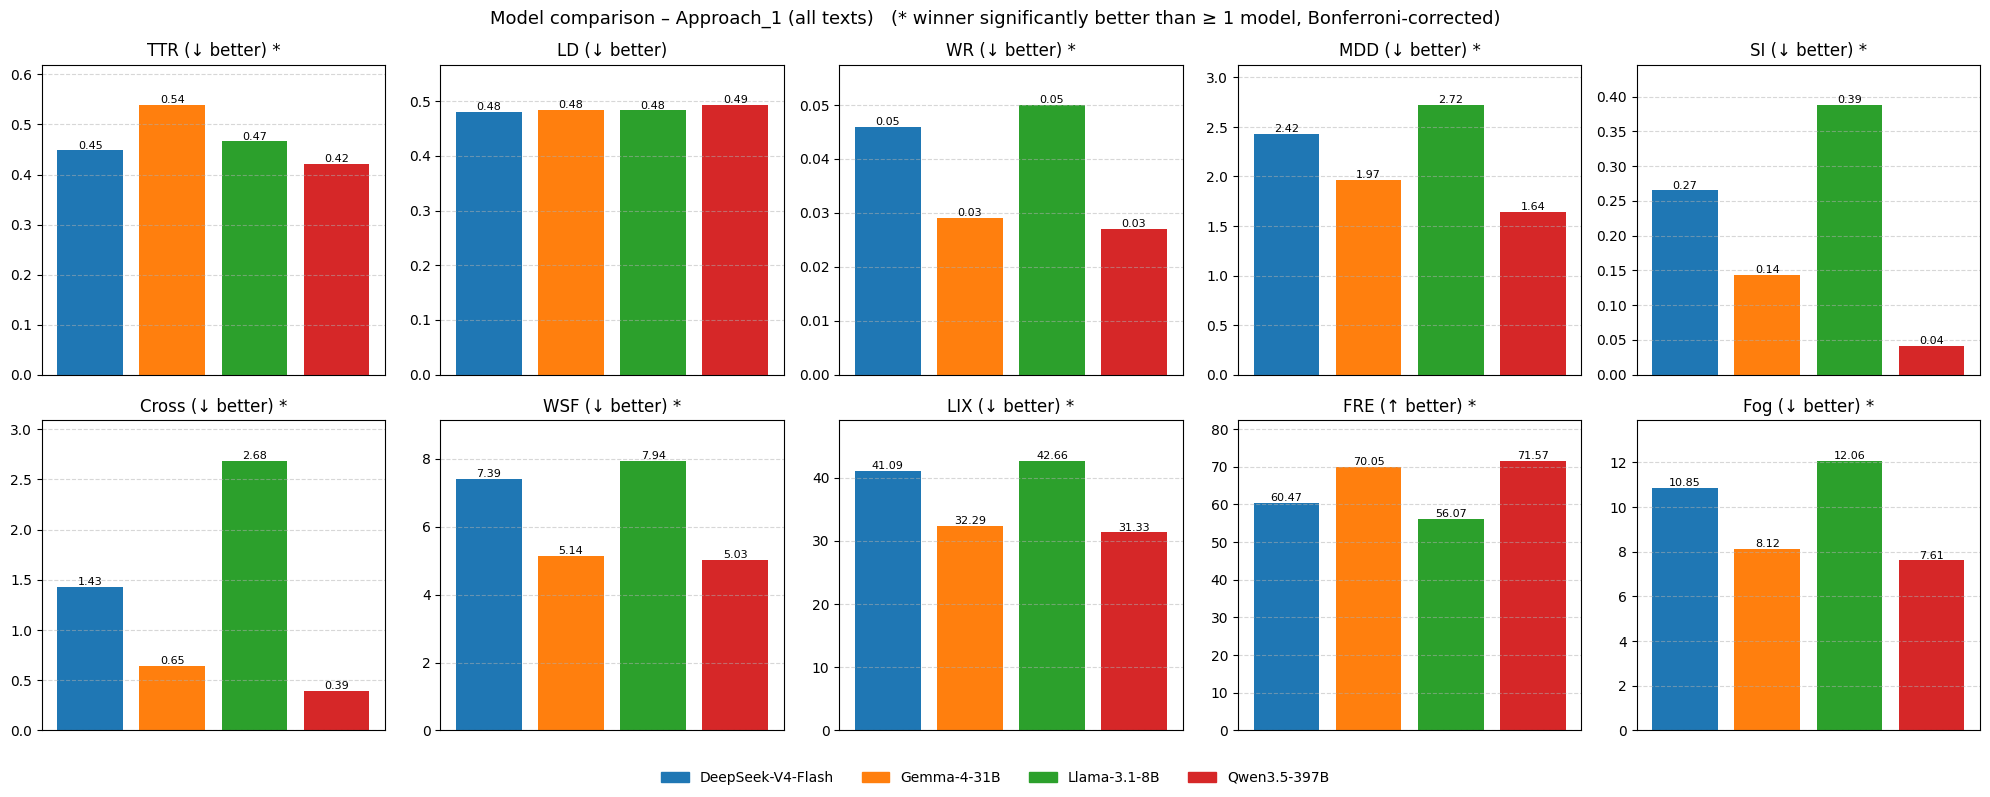

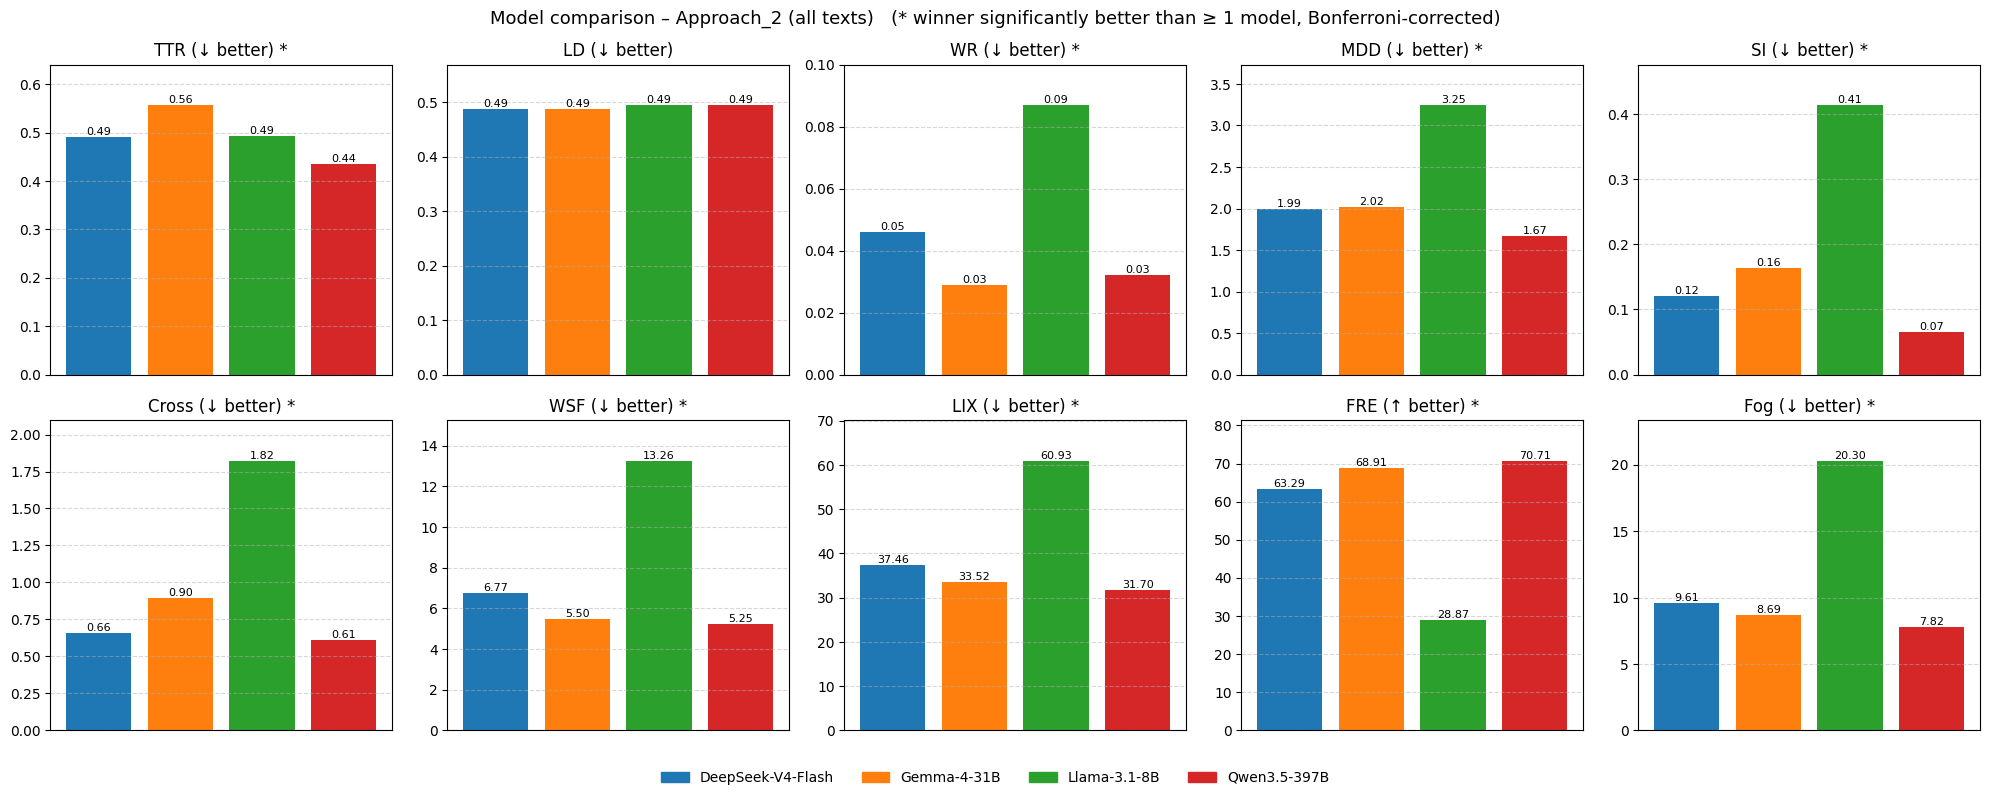

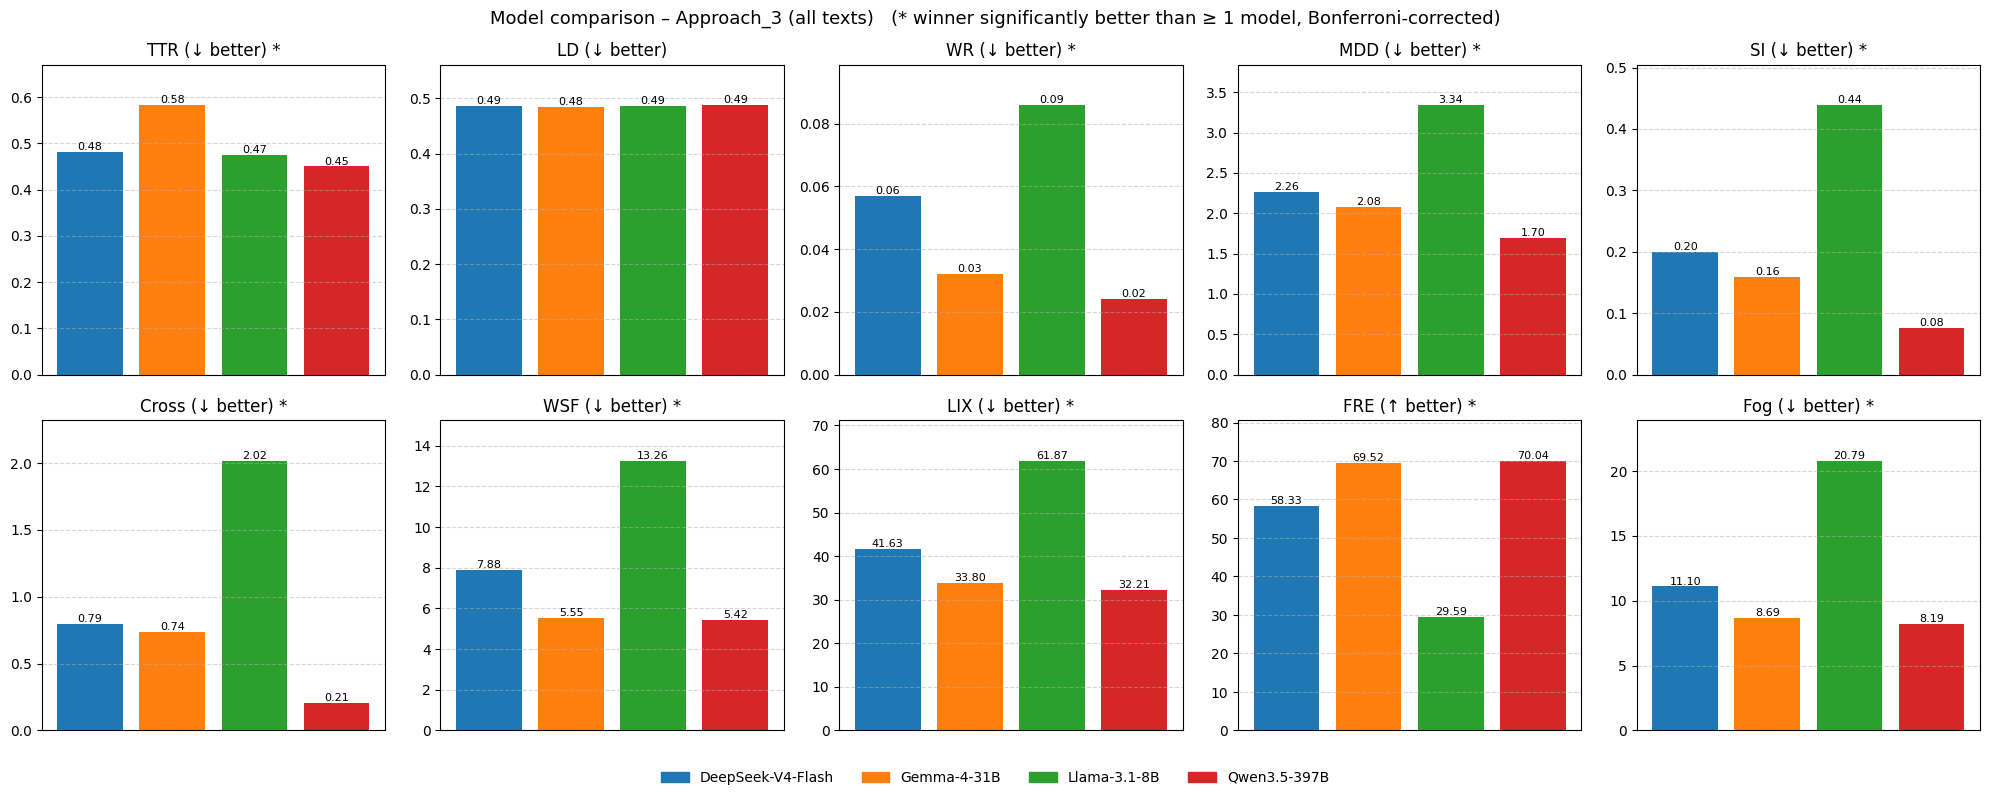

In [5]:
for version in APPROACHES:
    plot_model_comparison(results[version], f"Model comparison – {version} (all texts)", f"LLM_Comparison_{version}.png")

## Legal texts and medical texts separately (n = 5)

In [6]:
domain_wins = {}
for domain in ["Legal", "Medical"]:
    for version in APPROACHES:
        print(f"\n======================= {version} | {domain} =======================")
        res, wins_all, wins_sig = compare_models(scores, version, domain)
        domain_wins[(domain, version)] = wins_all
        print(res.drop(columns=["Significant_pairs", "Winner_better_than"]).to_string(index=False))
        print("Total wins (descriptive):", wins_all)
        res.to_csv(os.path.join(RESULTS_DIR, f"LLM_Comparison_{version}_{domain}.csv"), index=False)


======================= Approach_1 | Legal =======================
Metric  n  Friedman_p  Kendalls_W  DeepSeek-V4-Flash_mean  Gemma-4-31B_mean  Llama-3.1-8B_mean  Qwen3.5-397B_mean       Winner  Posthoc_result
   TTR  5    0.002851      0.9360                   0.497             0.564              0.468              0.421 Qwen3.5-397B Not Significant
    LD  5    0.781904      0.0720                   0.483             0.469              0.472              0.469 Qwen3.5-397B Not Significant
    WR  5    0.040835      0.5510                   0.049             0.028              0.025              0.031 Llama-3.1-8B Not Significant
   MDD  5    0.002851      0.9360                   2.565             2.012              2.755              1.706 Qwen3.5-397B Not Significant
    SI  5    0.002851      0.9360                   0.271             0.147              0.360              0.046 Qwen3.5-397B Not Significant
 Cross  5    0.043150      0.5429                   1.298             0.63


======================= Approach_1 | Medical =======================
Metric  n  Friedman_p  Kendalls_W  DeepSeek-V4-Flash_mean  Gemma-4-31B_mean  Llama-3.1-8B_mean  Qwen3.5-397B_mean            Winner  Posthoc_result
   TTR  5    0.050331      0.5200                   0.399             0.514              0.465              0.423 DeepSeek-V4-Flash Not Significant
    LD  5    0.240662      0.2800                   0.479             0.500              0.493              0.517 DeepSeek-V4-Flash Not Significant
    WR  5    0.004996      0.8560                   0.042             0.029              0.075              0.023      Qwen3.5-397B Not Significant
   MDD  5    0.002851      0.9360                   2.285             1.921              2.688              1.569      Qwen3.5-397B Not Significant
    SI  5    0.004996      0.8560                   0.258             0.139              0.417              0.037      Qwen3.5-397B Not Significant
 Cross  5    0.473450      0.1673         

## Summary: which model is best?

* **Wins** = number of metrics (out of 10) where the model has the best mean.
* **Significant wins** = wins where the model is significantly better than at least one other model.
* **Mean rank** = average rank of the model over the 10 metrics (1 = best, 4 = worst).

In [7]:
def mean_rank_table(results):
    table = {}
    for version, res in results.items():
        ranks = []
        for _, row in res.iterrows():
            means = pd.Series({m: row[f"{m}_mean"] for m in MODELS})
            ranks.append(means.rank(ascending=row["Metric"] not in HIGHER_BETTER))
        table[version] = pd.DataFrame(ranks).mean()
    table = pd.DataFrame(table)
    table["Overall"] = table.mean(axis=1)
    return table.round(2).sort_values("Overall")


wins_summary = pd.concat({
    "Wins": pd.DataFrame(wins_all_table),
    "Significant wins": pd.DataFrame(wins_sig_table),
}, axis=1)
wins_summary[("Wins", "Total")] = pd.DataFrame(wins_all_table).sum(axis=1)
wins_summary[("Significant wins", "Total")] = pd.DataFrame(wins_sig_table).sum(axis=1)
wins_summary = wins_summary.sort_index(axis=1, level=0, sort_remaining=False)
print("=========== Wins (all texts) ===========")
print(wins_summary)

print("\n=========== Descriptive wins per domain ===========")
print(pd.DataFrame(domain_wins))

rank_table = mean_rank_table(results)
print("\n=========== Mean rank (1 = best) ===========")
print(rank_table)

wins_summary.to_csv(os.path.join(RESULTS_DIR, "LLM_Comparison_Wins.csv"))
rank_table.to_csv(os.path.join(RESULTS_DIR, "LLM_Comparison_Mean_Rank.csv"))

=========== Wins (all texts) ===========
                  Significant wins                                   Wins                            
                        Approach_1 Approach_2 Approach_3 Total Approach_1 Approach_2 Approach_3 Total
DeepSeek-V4-Flash                0          0          0     0          1          1          0     2
Gemma-4-31B                      0          1          0     1          0          1          1     2
Llama-3.1-8B                     0          0          0     0          0          0          0     0
Qwen3.5-397B                     9          8          9    26          9          8          9    26

=========== Descriptive wins per domain ===========
                       Legal                          Medical                      
                  Approach_1 Approach_2 Approach_3 Approach_1 Approach_2 Approach_3
DeepSeek-V4-Flash          0          1          0          2          1          1
Gemma-4-31B                0          2   

In [8]:
# Mean rank per metric group (all approaches together)
def group_rank(results, metric_group):
    ranks = []
    for res in results.values():
        for _, row in res[res["Metric"].isin(metric_group)].iterrows():
            means = pd.Series({m: row[f"{m}_mean"] for m in MODELS})
            ranks.append(means.rank(ascending=row["Metric"] not in HIGHER_BETTER))
    return pd.DataFrame(ranks).mean()

group_ranks = pd.DataFrame({
    "Lexical": group_rank(results, LEXICAL_METRICS),
    "Syntactic": group_rank(results, SYNTACTIC_METRICS),
    "Readability": group_rank(results, READABILITY_METRICS),
}).round(2)
group_ranks

,Lexical,Syntactic,Readability
DeepSeek-V4-Flash,2.39,2.67,3.0
Gemma-4-31B,2.50,2.33,2.0
Llama-3.1-8B,3.06,4.00,4.0
Qwen3.5-397B,2.06,1.00,1.0


## Findings – which model is best?

* **Qwen3.5-397B is clearly the best model.**
  * It wins 26 of 30 metric × approach comparisons, and all 26 wins are significant.
  * It has a mean rank of 1.32 out of 4.
  * It has the best syntactic scores (MDD, SI, Cross) and readability scores (WSF, LIX, FRE, Fog) in every approach.
* **Gemma-4-31B is second** (mean rank 2.25), close to Qwen on readability. However, it has the **highest TTR** (least repetitive vocabulary).
* **DeepSeek-V4-Flash is third** (mean rank 2.72). It is mainly weaker on readability.
* **Llama-3.1-8B is clearly last** (mean rank 3.72).
  * In Approach_2 and Approach_3 its output stays almost standard German (e.g. LIX ≈ 61 vs. 62.6 for the Original).
  * It only simplifies in Approach_1.
* **Lexical Density** does not differ between models in any approach (Friedman p > 0.5).
* The results are the same for legal and medical texts: Qwen has the most wins in both domains. With n = 5 per domain the post-hoc tests cannot become significant, so the per-domain tables are descriptive only.

⚠️ These metrics measure **linguistic complexity only**. They do not measure content correctness or hallucinations, so a manual error analysis is still needed.
